## Test training (CHEAT)


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d]'
00: ===========================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin_cheat 94cb65af/last.pt'... done; this took 7.12ms.
01:   Model is ready. Current epoch to train is 1000.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin_cheat 94cb65af/.
00: Model 'AEC train_vol_vol_attin_cheat 1.2 [b28452c8|fa6007dd3ce42e6d]' was already trained for 1000 epochs.


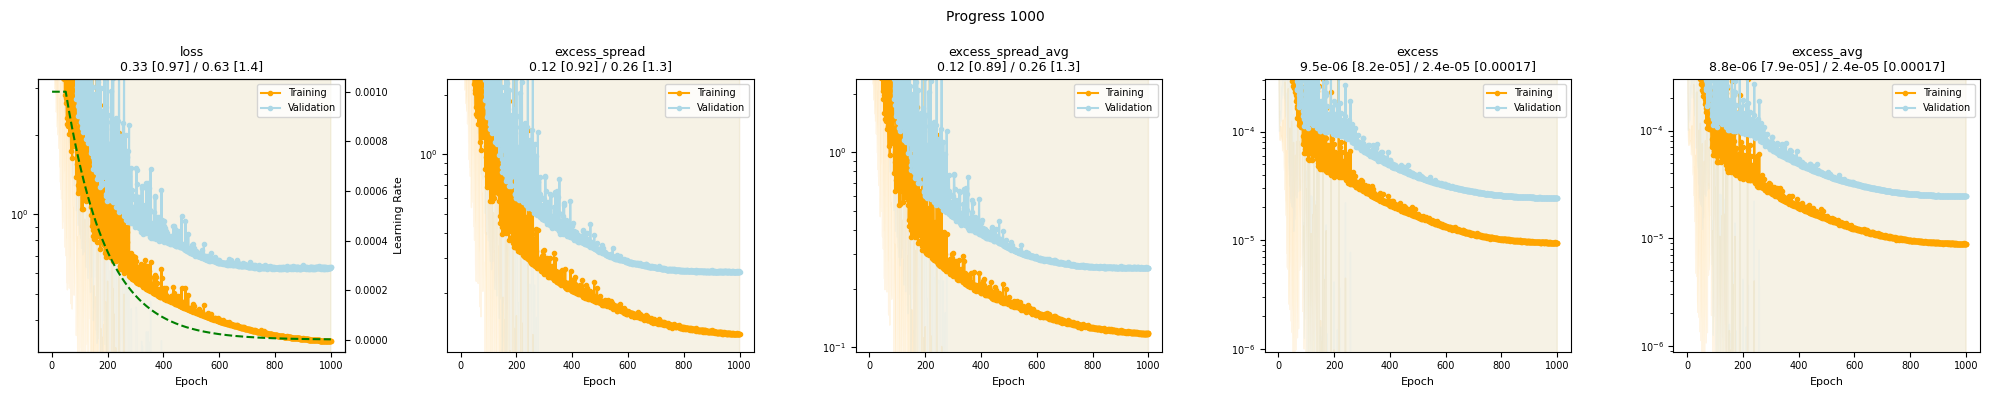

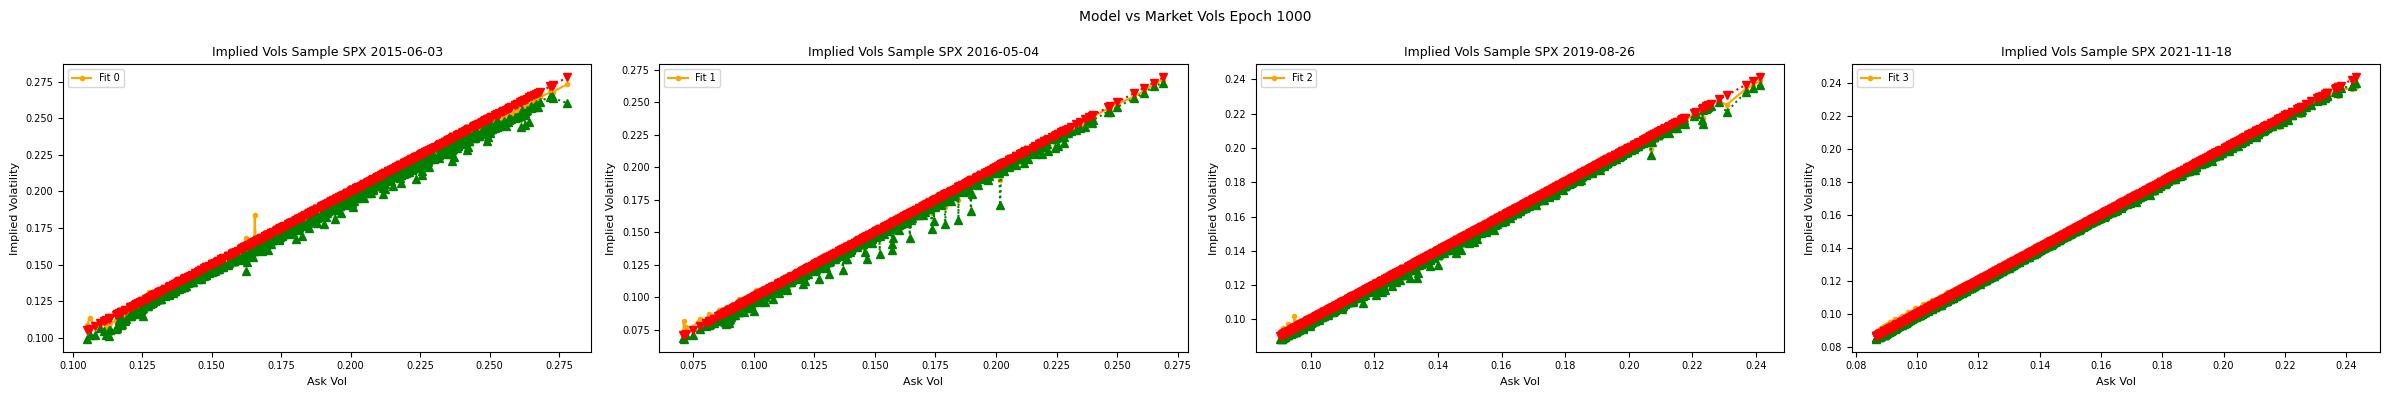

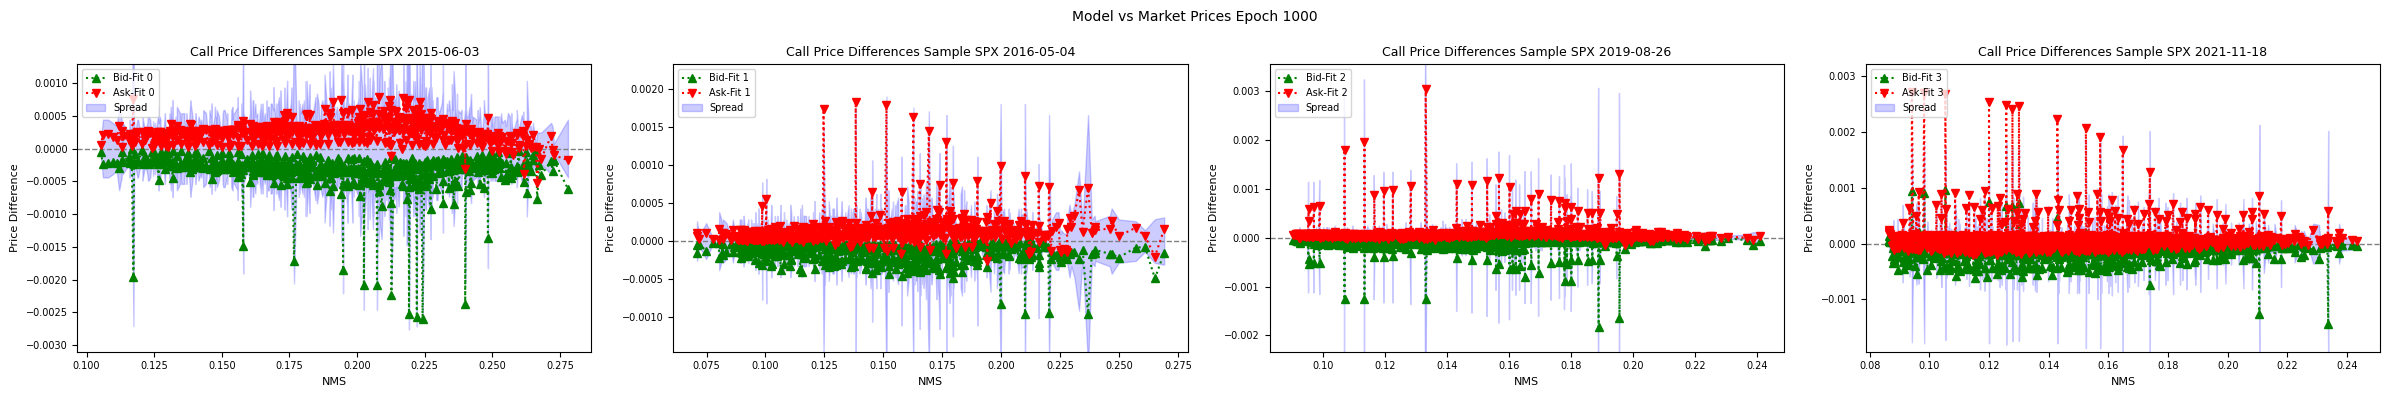

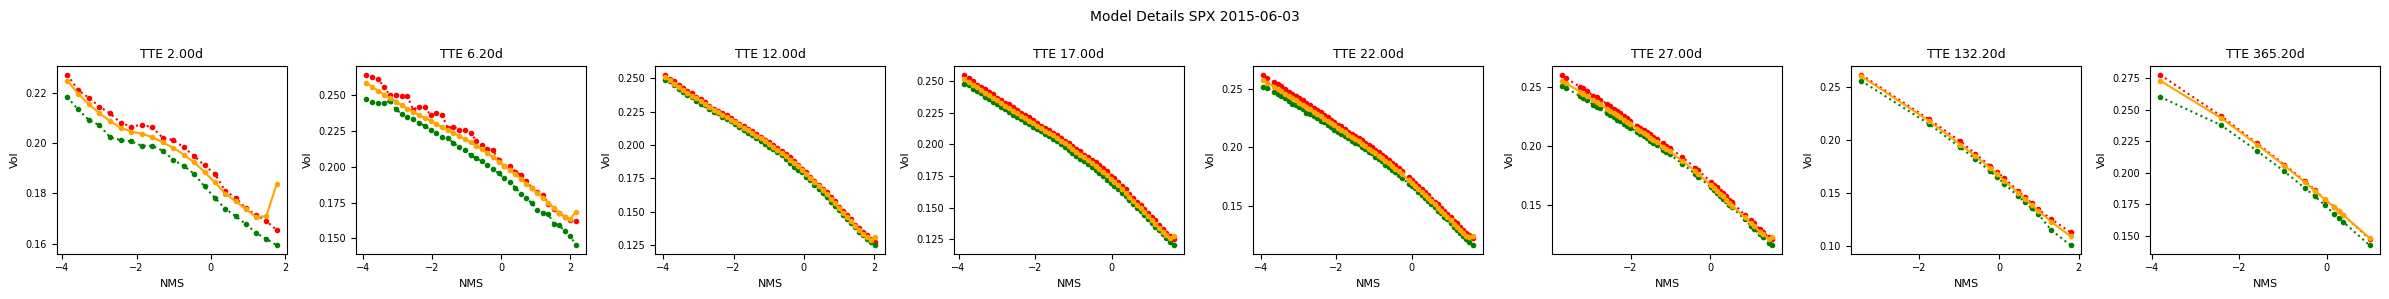

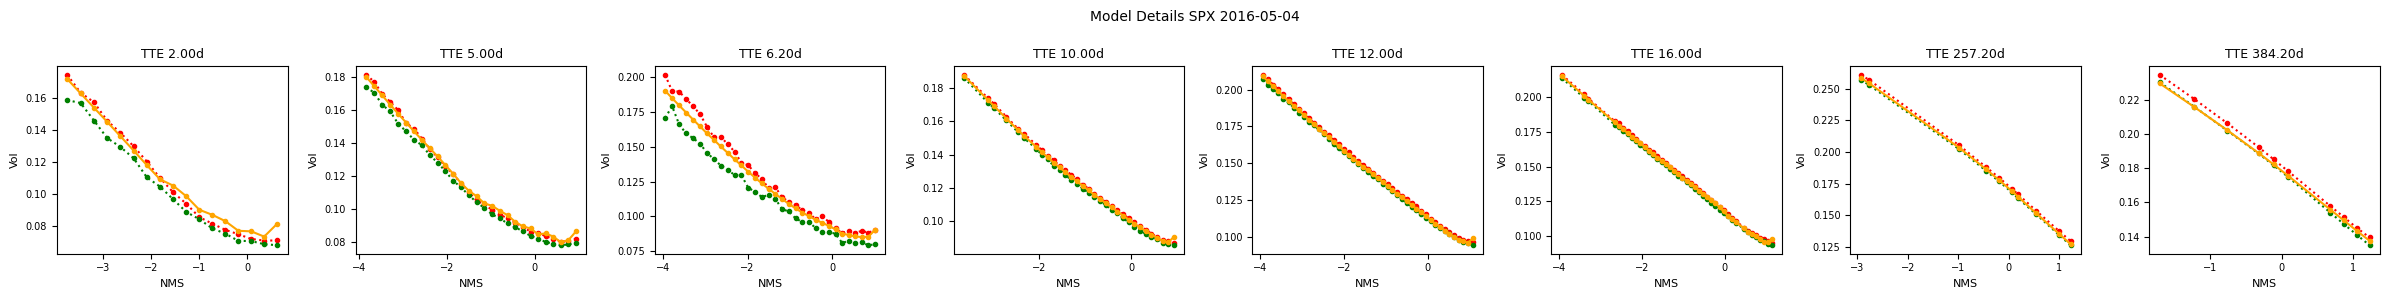

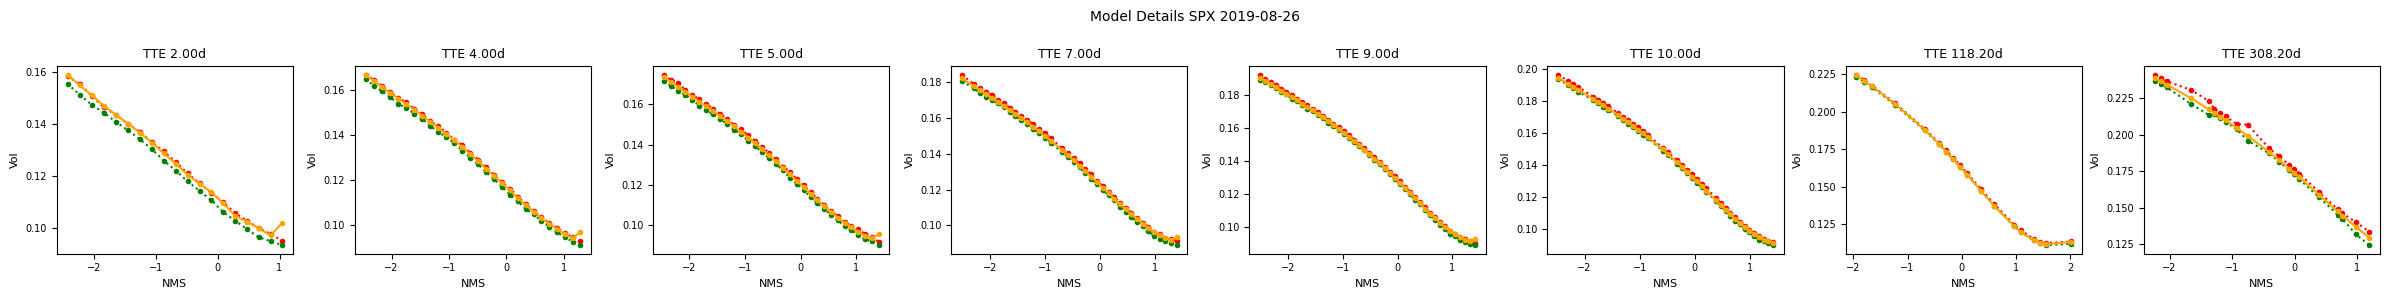

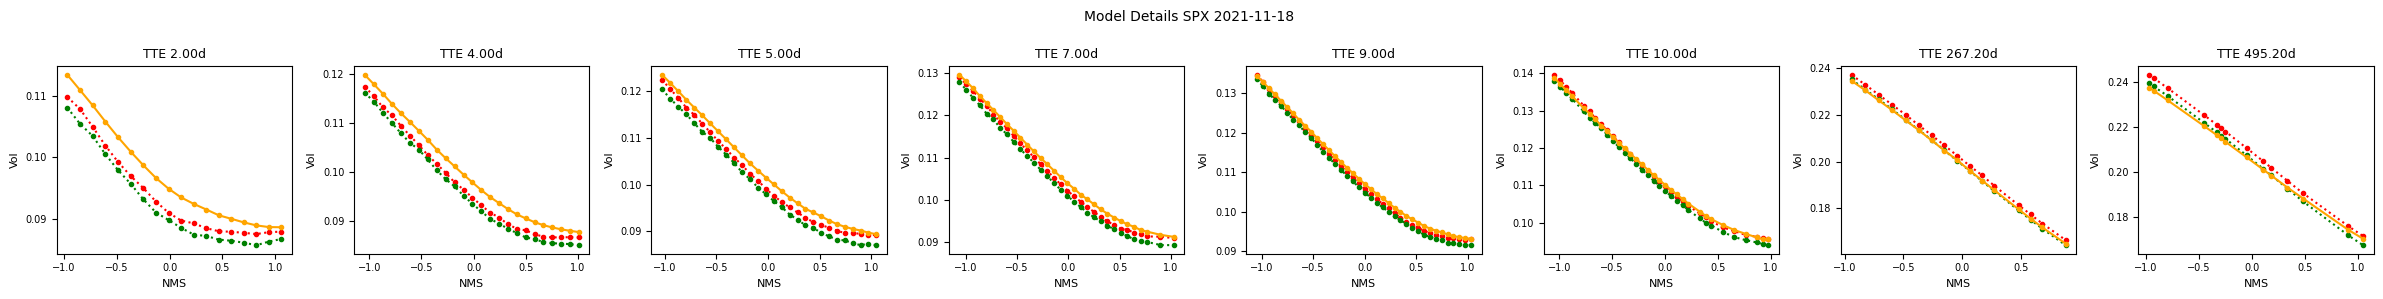

In [2]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,
    cheat = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )


In [3]:
sampler.data

{'SPX': PrettyObject({'dates': [datetime.date(2015, 1, 2), datetime.date(2015, 1, 5), datetime.date(2015, 1, 6), datetime.date(2015, 1, 7), datetime.date(2015, 1, 8), datetime.date(2015, 1, 9), datetime.date(2015, 1, 12), datetime.date(2015, 1, 13), datetime.date(2015, 1, 14), datetime.date(2015, 1, 15), datetime.date(2015, 1, 16), datetime.date(2015, 1, 20), datetime.date(2015, 1, 21), datetime.date(2015, 1, 22), datetime.date(2015, 1, 23), datetime.date(2015, 1, 26), datetime.date(2015, 1, 27), datetime.date(2015, 1, 28), datetime.date(2015, 1, 29), datetime.date(2015, 1, 30), datetime.date(2015, 2, 2), datetime.date(2015, 2, 3), datetime.date(2015, 2, 4), datetime.date(2015, 2, 5), datetime.date(2015, 2, 6), datetime.date(2015, 2, 9), datetime.date(2015, 2, 10), datetime.date(2015, 2, 11), datetime.date(2015, 2, 12), datetime.date(2015, 2, 13), datetime.date(2015, 2, 17), datetime.date(2015, 2, 18), datetime.date(2015, 2, 19), datetime.date(2015, 2, 20), datetime.date(2015, 2, 23), 